# StellarClass AI: Exploratory Data Analysis

**Dataset:** *Stellar Classification Dataset - SDSS17* (fedesoriano, Kaggle, 2022). It holds 100,000 objects
whose class was assigned by the SDSS spectroscopic pipeline, exported from **SDSS Data Release 17**.

**Goal of this notebook:** understand the data before modelling. We look at its structure, quality problems,
class balance, and which measured properties separate **stars** from **galaxies**.

Run from the repository root after `python -m src.data_loader`. All figures are also saved to `reports/figures/`.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import seaborn as sns

# Make the project's modules (config.py, src/) importable from the notebooks/ folder.
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import config  # noqa: E402
from src.data_loader import load_raw_data  # noqa: E402
from src.preprocessing import add_colour_features, clean_data  # noqa: E402

sns.set_theme(style="whitegrid", context="notebook")
PALETTE = {"GALAXY": "#4C72B0", "STAR": "#DD8452", "QSO": "#55A868"}
FIG_DIR = ROOT / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)


def save(fig, name):
    fig.tight_layout()
    fig.savefig(FIG_DIR / f"eda_{name}.png", dpi=120)

## 1. Dimensions, columns and data types

In [2]:
raw = load_raw_data(ROOT / "data" / "raw" / "star_classification.csv")
print(f"Rows: {raw.shape[0]:,}   Columns: {raw.shape[1]}")
raw.dtypes.to_frame("dtype")

Rows: 100,000   Columns: 18


,dtype
obj_ID,string
alpha,float64
delta,float64
u,float64
g,float64
r,float64
i,float64
z,float64
run_ID,int64
rerun_ID,int64


In [3]:
raw.head()

,obj_ID,alpha,delta,u,g,r,i,z,run_ID,rerun_ID,cam_col,field_ID,spec_obj_ID,class,redshift,plate,MJD,fiber_ID
0,1237660961327743232,135.689107,32.494632,23.87882,22.27530,20.39501,19.16573,18.79371,3606,301,2,79,6543777369295181824,GALAXY,0.634794,5812,56354,171
1,1237664879951151360,144.826101,31.274185,24.77759,22.83188,22.58444,21.16812,21.61427,4518,301,5,119,11760142036707334144,GALAXY,0.779136,10445,58158,427
2,1237660961330430208,142.188790,35.582444,25.26307,22.66389,20.60976,19.34857,18.94827,3606,301,2,120,5152200256025548800,GALAXY,0.644195,4576,55592,299
3,1237663478724297984,338.741038,-0.402828,22.13682,23.77656,21.61162,20.50454,19.25010,4192,301,3,214,10301071412954421248,GALAXY,0.932346,9149,58039,775
4,1237680272041378048,345.282593,21.183866,19.43718,17.58028,16.49747,15.97711,15.54461,8102,301,3,137,6891864880783316992,GALAXY,0.116123,6121,56187,842


**Column roles**

| Column(s) | Meaning | Used as model input? |
|---|---|---|
| `u, g, r, i, z` | Apparent magnitudes in the five SDSS filters (smaller = brighter) | **Yes** |
| `redshift` | Spectroscopic redshift | **Yes**, in the *full* model only |
| `class` | Spectroscopic class: GALAXY, STAR or QSO | **Target** |
| `obj_ID`, `spec_obj_ID` | Unique identifiers | No: identifiers |
| `alpha`, `delta` | Sky position (RA/Dec, J2000) | No: position on the sky, not an object property |
| `run_ID, rerun_ID, cam_col, field_ID` | Imaging scan bookkeeping | No: identifiers |
| `plate, MJD, fiber_ID` | Spectroscopic plate, date and fibre | No: can leak the target, since some plates were dedicated to stars |

## 2. Summary statistics

In [4]:
raw.describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
alpha,100000.0,177.629,96.502,0.006,127.518,180.901,233.895,360.000
delta,100000.0,24.135,19.645,-18.785,5.147,23.646,39.902,83.001
u,100000.0,21.980,31.769,-9999.000,20.352,22.179,23.687,32.781
g,100000.0,20.531,31.750,-9999.000,18.965,21.100,22.124,31.602
r,100000.0,19.646,1.855,9.822,18.136,20.125,21.045,29.572
i,100000.0,19.085,1.758,9.470,17.732,19.405,20.396,32.141
z,100000.0,18.669,31.728,-9999.000,17.461,19.005,19.921,29.384
run_ID,100000.0,4481.366,1964.765,109.000,3187.000,4188.000,5326.000,8162.000
rerun_ID,100000.0,301.000,0.000,301.000,301.000,301.000,301.000,301.000
cam_col,100000.0,3.512,1.587,1.000,2.000,4.000,5.000,6.000


## 3. Missing values, duplicates and invalid values

In [5]:
print("Missing values per column:")
print(raw.isna().sum().to_string())
print(f"\nExact duplicate rows: {raw.duplicated().sum()}")
print(f"Duplicate object IDs: {raw['obj_ID'].duplicated().sum()}")
mags = config.MAGNITUDE_COLUMNS
sentinel_rows = raw[(raw[mags] <= config.SENTINEL_VALUE).any(axis=1)]
print(f"\nRows containing the SDSS sentinel value -9999: {len(sentinel_rows)}")
sentinel_rows[mags + ["redshift", "class"]]

Missing values per column:
obj_ID         0
alpha          0
delta          0
u              0
g              0
r              0
i              0
z              0
run_ID         0
rerun_ID       0
cam_col        0
field_ID       0
spec_obj_ID    0
class          0
redshift       0
plate          0
MJD            0
fiber_ID       0



Exact duplicate rows: 0
Duplicate object IDs: 19154

Rows containing the SDSS sentinel value -9999: 1


,u,g,r,i,z,redshift,class
79543,-9999.0,-9999.0,18.1656,18.01675,-9999.0,0.000089,STAR


The file has no missing values and no duplicate rows. Exactly **one** row (a STAR) holds the sentinel `-9999` in
`u`, `g` and `z`. That value means "no measurement", not a real magnitude. It would distort the distributions
and scaling, so it is removed. The `describe()` table above shows a `u` minimum of -9999 caused by this one row.

## 4. Target class distribution

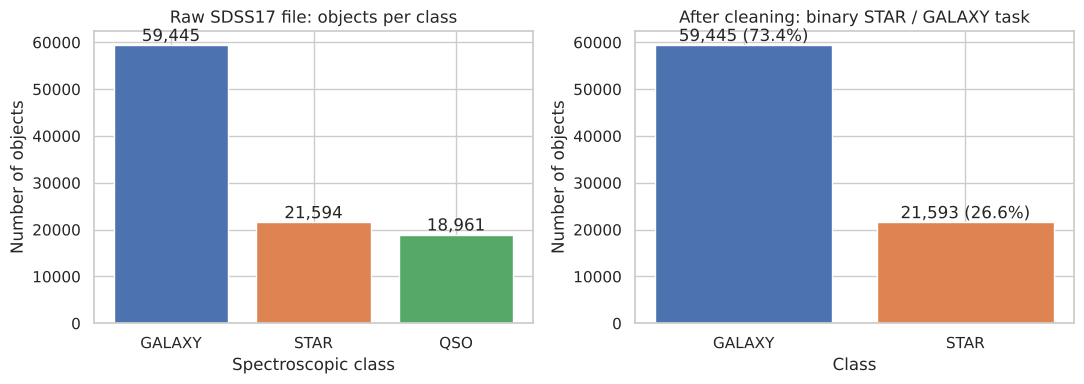

{'raw_rows': 100000,
 'raw_class_counts': {'GALAXY': 59445, 'STAR': 21594, 'QSO': 18961},
 'removed_other_classes': 18961,
 'removed_missing_values': 0,
 'removed_sentinel_or_non_finite': 1,
 'removed_duplicates': 0,
 'clean_rows': 81038,
 'clean_class_counts': {'GALAXY': 59445, 'STAR': 21593},
 'features_kept': ['u', 'g', 'r', 'i', 'z', 'redshift'],
 'columns_excluded_as_identifiers_or_leakage': ['obj_ID',
  'alpha',
  'delta',
  'run_ID',
  'rerun_ID',
  'cam_col',
  'field_ID',
  'spec_obj_ID',
  'plate',
  'MJD',
  'fiber_ID']}

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
counts = raw["class"].value_counts()
axes[0].bar(counts.index, counts.values, color=[PALETTE[c] for c in counts.index])
axes[0].set_title("Raw SDSS17 file: objects per class")
axes[0].set_xlabel("Spectroscopic class")
axes[0].set_ylabel("Number of objects")
for k, v in enumerate(counts.values):
    axes[0].text(k, v, f"{v:,}", ha="center", va="bottom")

clean, report = clean_data(raw)
bc = clean["class"].value_counts()
axes[1].bar(bc.index, bc.values, color=[PALETTE[c] for c in bc.index])
axes[1].set_title("After cleaning: binary STAR / GALAXY task")
axes[1].set_xlabel("Class")
axes[1].set_ylabel("Number of objects")
for k, v in enumerate(bc.values):
    axes[1].text(k, v, f"{v:,} ({v / bc.sum():.1%})", ha="center", va="bottom")
save(fig, "class_distribution")
plt.show()
report

**Interpretation.** The project is binary, so the 18,961 QSO (quasar) rows are removed. After cleaning,
**81,038** objects remain and they are **imbalanced**: about 73% galaxies and 27% stars. A model that always
predicts "GALAXY" would already score about 73% accuracy, so we also report precision, recall, F1 for the STAR
class, balanced accuracy and ROC-AUC, and compare against that majority-class baseline.

## 5. Feature distributions by class

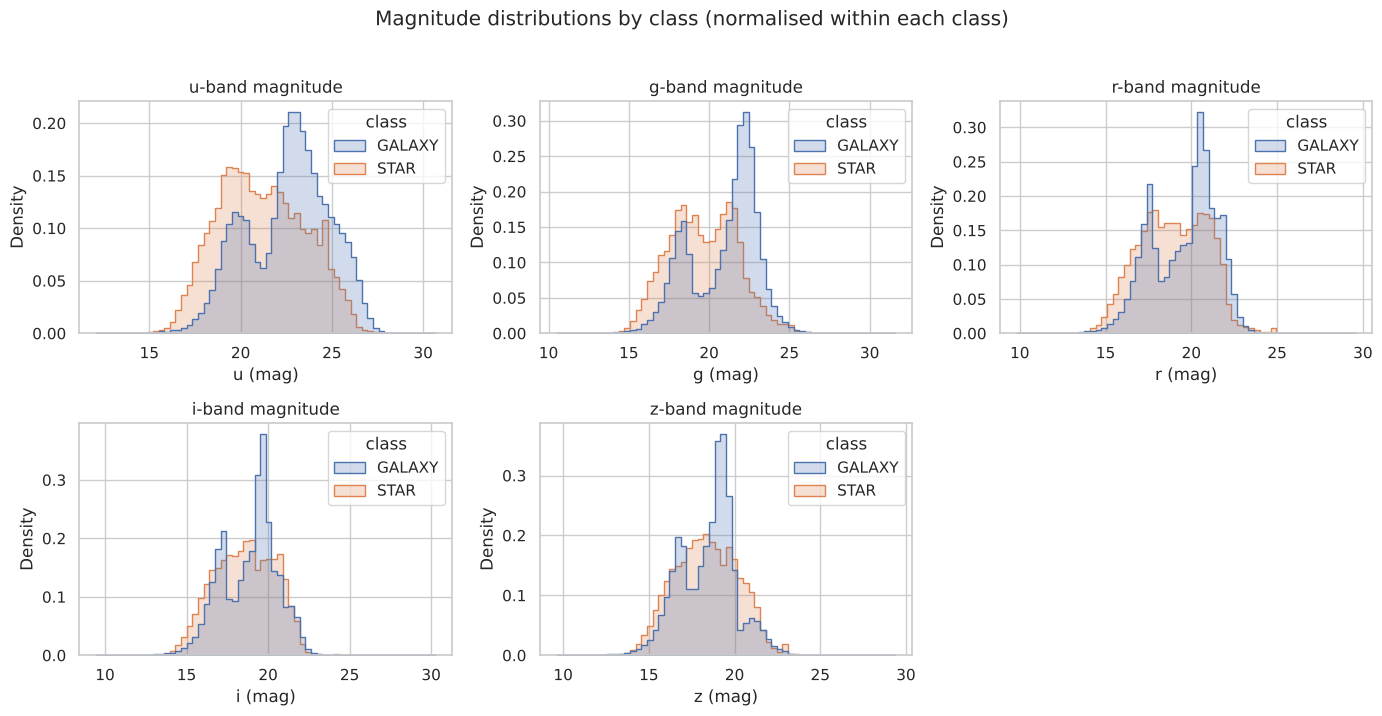

In [7]:
data = add_colour_features(clean[mags])
data["redshift"] = clean["redshift"]
data["class"] = clean["class"]

fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, col in zip(axes.ravel()[: len(mags)], mags, strict=True):
    sns.histplot(
        data=data,
        x=col,
        hue="class",
        palette=PALETTE,
        bins=60,
        stat="density",
        common_norm=False,
        element="step",
        ax=ax,
    )
    ax.set_title(f"{col}-band magnitude")
    ax.set_xlabel(f"{col} (mag)")
    ax.set_ylabel("Density")
axes.flat[-1].axis("off")
fig.suptitle("Magnitude distributions by class (normalised within each class)", y=1.02)
save(fig, "magnitude_distributions")
plt.show()

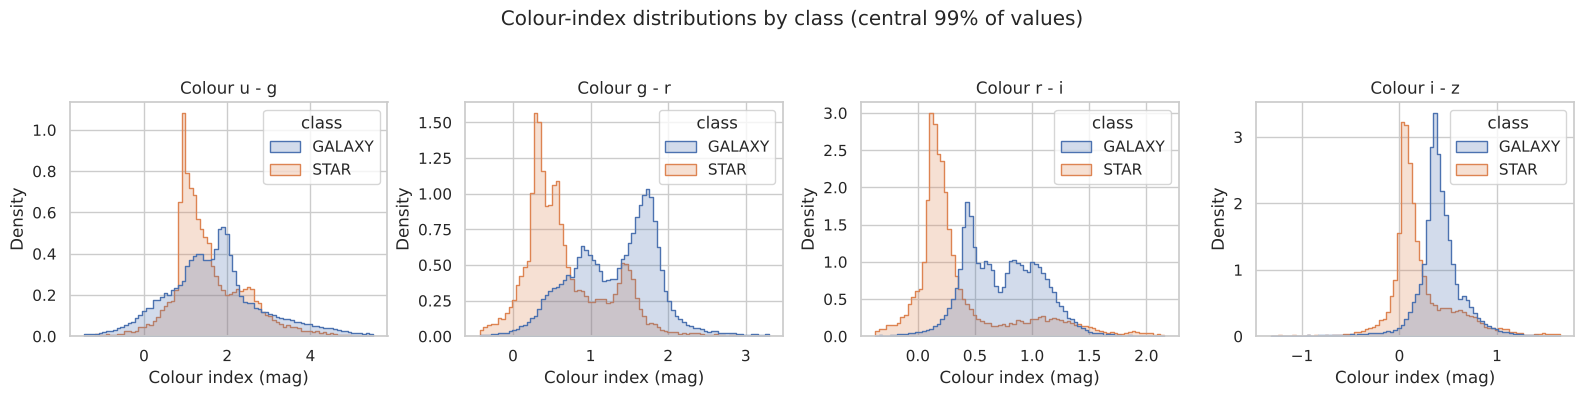

class,GALAXY,STAR
u,22.842,21.011
g,21.582,19.543
r,20.105,18.955
i,19.224,18.592
z,18.767,18.319
u_g,1.640,1.319
g_r,1.404,0.527
r_i,0.720,0.211
i_z,0.391,0.116
redshift,0.456,-0.000


In [8]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.8))
for ax, col in zip(axes, ["u_g", "g_r", "r_i", "i_z"], strict=True):
    sns.histplot(
        data=data,
        x=col,
        hue="class",
        palette=PALETTE,
        bins=80,
        stat="density",
        common_norm=False,
        element="step",
        ax=ax,
        binrange=tuple(data[col].quantile([0.005, 0.995])),
    )
    ax.set_title(f"Colour {col.replace('_', ' - ')}")
    ax.set_xlabel("Colour index (mag)")
    ax.set_ylabel("Density")
fig.suptitle("Colour-index distributions by class (central 99% of values)", y=1.04)
save(fig, "colour_distributions")
plt.show()
data.groupby("class")[mags + ["u_g", "g_r", "r_i", "i_z", "redshift"]].median().T.round(3)

**Interpretation.**
* In every band, galaxies in this sample are fainter (larger magnitudes) than stars. The median `u` is about
  22.8 for galaxies and 21.0 for stars. Brightness depends on distance and on how SDSS chose its spectroscopic
  targets, so it says little about an object's physical type by itself.
* Colours (differences between bands) separate the classes more clearly. Galaxies in this sample are redder:
  the median `g - r` is about 1.40 for galaxies and 0.53 for stars. Even so, the histograms overlap substantially.
  Photometry alone cannot separate every object.

## 6. Redshift

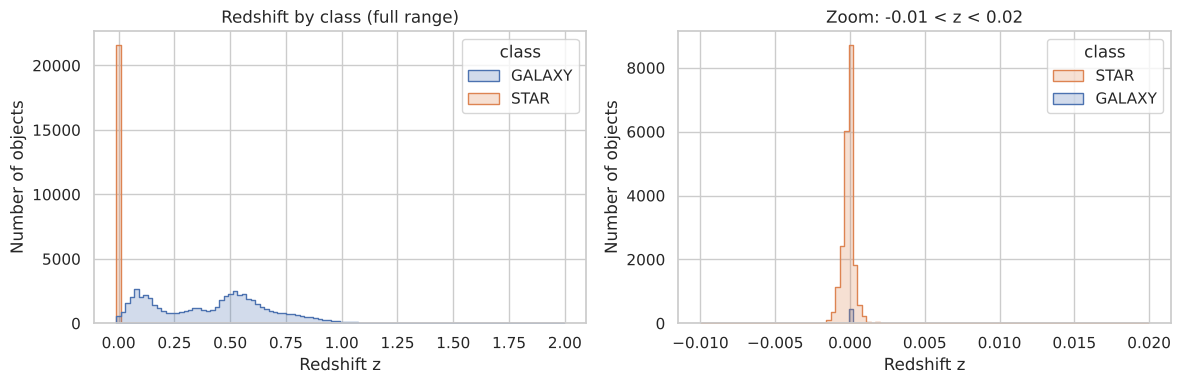

          count     mean      std      min      25%      50%      75%      max
class                                                                         
GALAXY  59445.0  0.42160  0.26486 -0.00997  0.16453  0.45627  0.59470  1.99552
STAR    21593.0 -0.00011  0.00047 -0.00414 -0.00030 -0.00008  0.00008  0.00415

Galaxies with z < 0.005: 525
Stars with z > 0.005:    0


In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(data=data, x="redshift", hue="class", palette=PALETTE, bins=100, element="step", ax=axes[0])
axes[0].set_title("Redshift by class (full range)")
axes[0].set_xlabel("Redshift z")
axes[0].set_ylabel("Number of objects")
zoom = data[data["redshift"].between(-0.01, 0.02)]
sns.histplot(data=zoom, x="redshift", hue="class", palette=PALETTE, bins=100, element="step", ax=axes[1])
axes[1].set_title("Zoom: -0.01 < z < 0.02")
axes[1].set_xlabel("Redshift z")
axes[1].set_ylabel("Number of objects")
save(fig, "redshift")
plt.show()
print(data.groupby("class")["redshift"].describe().round(5))
print("\nGalaxies with z < 0.005:", int(((data["class"] == "GALAXY") & (data["redshift"] < 0.005)).sum()))
print("Stars with z > 0.005:   ", int(((data["class"] == "STAR") & (data["redshift"] > 0.005)).sum()))

**Interpretation.** Redshift is by far the strongest single feature. Every star in the dataset has |z| < 0.005,
because stars belong to our own galaxy and their small redshifts come from their own motion. Most galaxies have
z between about 0.1 and 0.7. Only **525** of 59,445 galaxies have z < 0.005, and those nearby galaxies are where
confusion is possible.

**Caveat for real-world use.** Redshift is measured from a *spectrum*. The SDSS spectroscopic pipeline already
assigns a class once it has a spectrum. So a model that uses redshift mainly shows how well this cheap
measurement summarises the pipeline's decision. The more useful scenario is classifying the many objects that
only have *photometry* (the five magnitudes). This is why the project also trains a **photometry-only** model.

## 7. Correlations

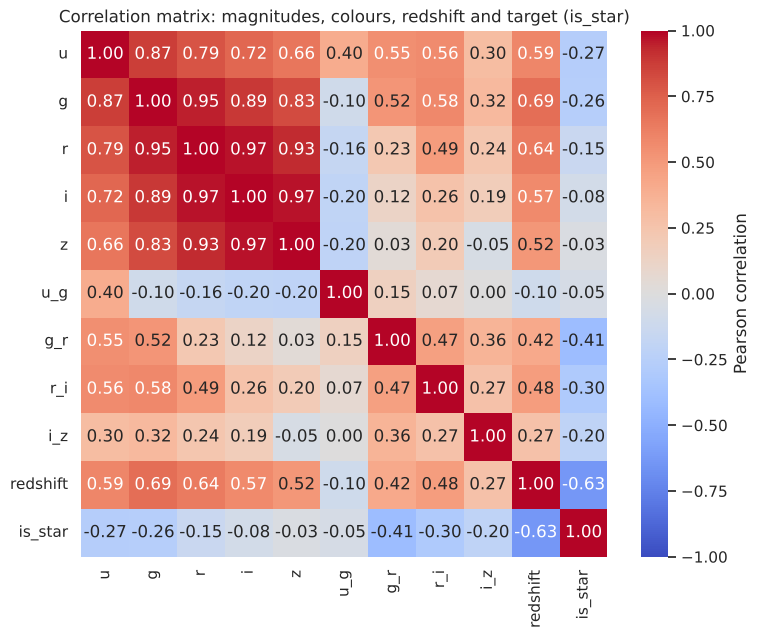

redshift   -0.635
g_r        -0.412
r_i        -0.302
u          -0.267
g          -0.261
i_z        -0.204
r          -0.147
i          -0.078
u_g        -0.055
z          -0.030
Name: is_star, dtype: float64

In [10]:
fig, ax = plt.subplots(figsize=(8, 6.5))
corr = data.drop(columns="class").assign(is_star=(data["class"] == "STAR").astype(int)).corr()
sns.heatmap(
    corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    square=True,
    ax=ax,
    cbar_kws={"label": "Pearson correlation"},
)
ax.set_title("Correlation matrix: magnitudes, colours, redshift and target (is_star)")
save(fig, "correlation_heatmap")
plt.show()
corr["is_star"].drop("is_star").sort_values().round(3)

**Interpretation.** The five magnitudes are strongly correlated with each other (r between 0.66 and 0.97),
because a bright object tends to be bright in every band. They carry overlapping information. This is one reason
we add colour indices, which are much less correlated with each other. `redshift` has the strongest (negative)
linear correlation with `is_star`. Pearson correlation captures only *linear* relationships. A tree model can use
non-linear patterns that do not show up here.

## 8. Feature relationships (scatter plots)

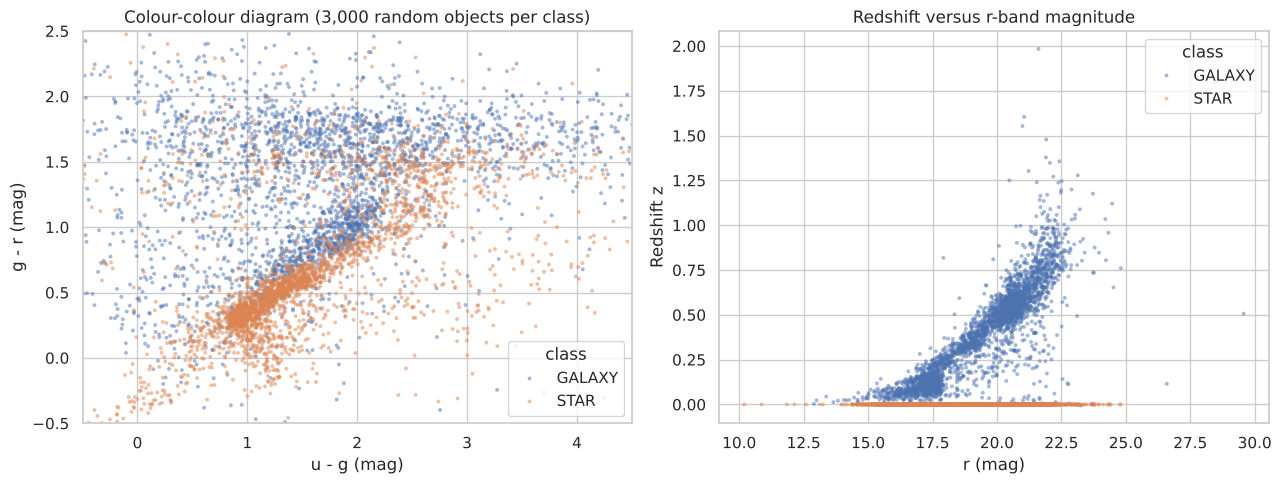

In [11]:
sample = data.groupby("class", group_keys=False).sample(n=3000, random_state=config.RANDOM_STATE)
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.scatterplot(data=sample, x="u_g", y="g_r", hue="class", palette=PALETTE, s=8, alpha=0.5, ax=axes[0], linewidth=0)
axes[0].set_xlim(-0.5, 4.5)
axes[0].set_ylim(-0.5, 2.5)
axes[0].set_title("Colour-colour diagram (3,000 random objects per class)")
axes[0].set_xlabel("u - g (mag)")
axes[0].set_ylabel("g - r (mag)")
sns.scatterplot(data=sample, x="r", y="redshift", hue="class", palette=PALETTE, s=8, alpha=0.5, ax=axes[1], linewidth=0)
axes[1].set_title("Redshift versus r-band magnitude")
axes[1].set_xlabel("r (mag)")
axes[1].set_ylabel("Redshift z")
save(fig, "scatter_relationships")
plt.show()

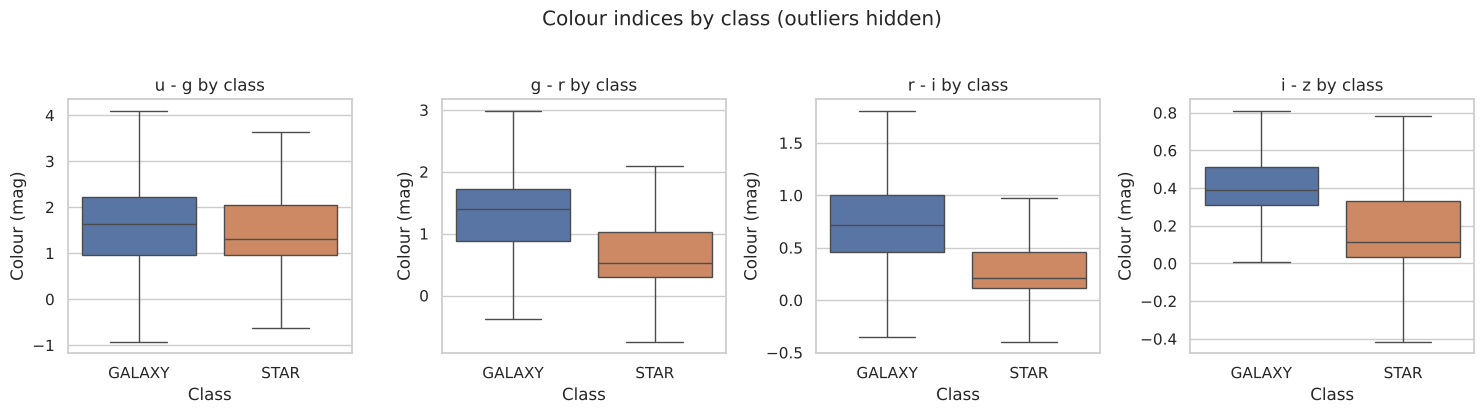

In [12]:
fig, axes = plt.subplots(1, 4, figsize=(15, 4))
for ax, col in zip(axes, ["u_g", "g_r", "r_i", "i_z"], strict=True):
    sns.boxplot(data=data, x="class", y=col, hue="class", palette=PALETTE, ax=ax, showfliers=False, legend=False)
    ax.set_title(f"{col.replace('_', ' - ')} by class")
    ax.set_xlabel("Class")
    ax.set_ylabel("Colour (mag)")
fig.suptitle("Colour indices by class (outliers hidden)", y=1.03)
save(fig, "colour_boxplots")
plt.show()

**Interpretation.** In the colour-colour diagram, stars form a fairly narrow sequence (the stellar locus).
Galaxies spread over a wider region, mostly at redder `g - r`. The two populations still overlap, especially
where the galaxy cloud meets the stellar locus (roughly u - g between 1.5 and 2.5, g - r between 0.7 and 1.5).
The redshift plot shows the separation is almost perfect in that dimension: stars sit on the z ≈ 0 line.

## 9. Summary of findings
1. **Quality:** no missing values or duplicates. One row with sentinel `-9999` magnitudes is removed. QSO rows are
   removed for the binary task, which leaves **81,038** objects.
2. **Imbalance:** about 73% galaxies and 27% stars. We use stratified splits and report F1, recall, balanced accuracy
   and ROC-AUC, not just accuracy.
3. **Redshift** separates the classes almost perfectly in this sample, but it requires a spectrum.
4. **Colours** carry real but overlapping information. The classes cannot be separated perfectly from photometry
   alone, and a non-linear model such as a Random Forest is expected to help.
5. Identifiers, sky position and plate/fibre/date columns are excluded to avoid leakage.

These are statements about *this* spectroscopic sample. SDSS chose which objects to observe spectroscopically,
so the brightness and redshift distributions are not representative of all objects in the sky.